UTS GSD 

Nama : Metha Nailis Sa'adah

Kelas : 2023A

NIM : 23031554159

## 2.1

In [ ]:
import pandas as pd
from neo4j import GraphDatabase

# Koneksi Neo4j
URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "password"

CSV_PATH = r"C:\Users\metli\TRY\.vscode\GSD uts\events.csv"
BATCH_SIZE = 5000

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

In [2]:
df = pd.read_csv("events.csv")

print("Ukuran data:", df.shape)
print("Nama kolom:", df.columns.tolist())
display(df.head())


Ukuran data: (2756101, 5)
Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


P1 : 2015-05-22 sampai sebelum 2015-06-01

P2 : 2015-08-01 sampai sebelum 2015-08-01


In [ ]:
df["datetime"] = pd.to_datetime(df["timestamp"], unit="ms")

p1 = df[
    (df["datetime"] >= "2015-05-22") &
    (df["datetime"] < "2015-06-01")
].copy()

p2 = df[
    (df["datetime"] >= "2015-08-01") &
    (df["datetime"] < "2015-08-11")
].copy()

p1.to_csv("retailrocket_P1_training.csv", index=False)
p2.to_csv("retailrocket_P2_testing.csv", index=False)

print("Jumlah baris P1:", len(p1))
print("Jumlah baris P2:", len(p2))
print("CSV P1 dan P2 berhasil disimpan.")

Jumlah baris P1: 196538
Jumlah baris P2: 177662
CSV P1 dan P2 berhasil disimpan.


BAGIAN 3

In [5]:
start = int(
    pd.Timestamp("2015-05-22", tz="UTC").timestamp() * 1000
)

end = int(
    pd.Timestamp("2015-06-01", tz="UTC").timestamp() * 1000
)

print("Periode P1: 22 Mei 2015 sampai sebelum 1 Juni 2015")
print("Parameter start:", start)
print("Parameter end:", end)

Periode P1: 22 Mei 2015 sampai sebelum 1 Juni 2015
Parameter start: 1432252800000
Parameter end: 1433116800000


In [6]:
query_komposisi = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.timestamp >= $start
  AND r.timestamp < $end
RETURN count(r) AS total_interaksi,
       count(DISTINCT v) AS jumlah_visitor,
       count(DISTINCT i) AS jumlah_item
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_komposisi,
        start=start,
        end=end
    )

    record = result.single()

    print("=== KOMPOSISI SUBGRAPH P1 ===")
    print(dict(record))

=== KOMPOSISI SUBGRAPH P1 ===
{'total_interaksi': 196538, 'jumlah_visitor': 108585, 'jumlah_item': 61143}


In [7]:
query_relasi = """
MATCH (:Visitor)-[r]->(:Item)
WHERE r.timestamp >= $start
  AND r.timestamp < $end
RETURN type(r) AS jenis_relasi,
       count(r) AS jumlah
ORDER BY jumlah DESC
"""

with driver.session(database="neo4j") as session:
    result = session.run(
        query_relasi,
        start=start,
        end=end
    )

    print("=== JENIS DAN JUMLAH RELASI P1 ===")

    for record in result:
        print(dict(record))

=== JENIS DAN JUMLAH RELASI P1 ===
{'jenis_relasi': 'VIEWED', 'jumlah': 190368}
{'jenis_relasi': 'ADDED_TO_CART', 'jumlah': 4660}
{'jenis_relasi': 'BOUGHT', 'jumlah': 1510}


Berdasarkan subgraph P1 diketahui pada periode 22 Mei 2015 hingga sebelum 1 Juni 2015 memiliki jumlah node visitor sebanyak 108.585 dan node item sebanyak 61.143, dengan total 196.538 relasi interaksi. relasi VIEWD adalah jenis interaksi terbanyak, diikuti ADDED_TO_CHART dan BOUGHT. hasil ini menunjukkan aktivitas pengguna didominasi oleh melihat produk, dibanding interaksi pembelian. 

Query cypher menggunkan MATCH untuk mengambil hubungan antara node Visitor dan Item. WHERE adalah klausa untuk menyaring relasi berdasarkan nilai timestamp berinteraksi dalam periode P1. 

BAGIAN 4 - VSM USER

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from pathlib import Path
from scipy.sparse import csr_matrix

In [9]:
p1 = Path("retailrocket_P1_training.csv")

if not p1.exists():
    raise FileNotFoundError(
        "File retailrocket_P1_training.csv tidak ditemukan. "
        "Pastikan file berada di folder kerja notebook."
    )

df_p1 = pd.read_csv(p1)

print("Ukuran data P1:", df_p1.shape)
print("Nama kolom:", df_p1.columns.tolist())

display(df_p1.head())

Ukuran data P1: (196538, 6)
Nama kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime']


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1432253007974,973650,view,342736,NaN,2015-05-22 00:03:27.974
1,1432252945016,117211,view,364251,NaN,2015-05-22 00:02:25.016
2,1432252944810,11580,view,152863,NaN,2015-05-22 00:02:24.810
3,1432253005273,1192719,view,193380,NaN,2015-05-22 00:03:25.273
4,1432252838573,527307,view,87063,NaN,2015-05-22 00:00:38.573


In [10]:
# Ambil kolom yang diperlukan
user_item = df_p1[["visitorid", "itemid"]].dropna().copy()

# Satu pasangan User-Item cukup direpresentasikan satu kali
user_item = user_item.drop_duplicates(
    subset=["visitorid", "itemid"]
)

# Bentuk daftar User dan Item
users = sorted(user_item["visitorid"].unique())
items = sorted(user_item["itemid"].unique())

# Ubah ID menjadi indeks numerik
user_to_idx = {user: idx for idx, user in enumerate(users)}
item_to_idx = {item: idx for idx, item in enumerate(items)}

rows = user_item["visitorid"].map(user_to_idx).to_numpy()
cols = user_item["itemid"].map(item_to_idx).to_numpy()
values = np.ones(len(user_item), dtype=np.int8)

print("Jumlah User unik:", len(users))
print("Jumlah Item unik:", len(items))
print("Jumlah pasangan User-Item unik:", len(user_item))

Jumlah User unik: 108585
Jumlah Item unik: 61143
Jumlah pasangan User-Item unik: 155574


In [14]:
user_vsm = csr_matrix(
    (values, (rows, cols)),
    shape=(len(users), len(items)),
    dtype=np.int8
)

print("=== KARAKTERISTIK USER VSM ===")
print("Dimensi matriks:", user_vsm.ndim)
print("Shape matriks:", user_vsm.shape)
print("Jumlah baris (User):", user_vsm.shape[0])
print("Jumlah kolom (fitur Item):", user_vsm.shape[1])
print("Jumlah nilai nonzero:", user_vsm.nnz)

total_elemen = user_vsm.shape[0] * user_vsm.shape[1]
sparsity = 1 - (user_vsm.nnz / total_elemen)

print(f"Sparsity matriks: {sparsity:.6%}")
print(f"Persentase interaksi terisi: {(1-sparsity):.6%}")

=== KARAKTERISTIK USER VSM ===
Dimensi matriks: 2
Shape matriks: (108585, 61143)
Jumlah baris (User): 108585
Jumlah kolom (fitur Item): 61143
Jumlah nilai nonzero: 155574
Sparsity matriks: 99.997657%
Persentase interaksi terisi: 0.002343%


In [12]:
jumlah_user_sampel = min(5, len(users))
jumlah_item_sampel = min(10, len(items))

sampel_vsm = pd.DataFrame(
    user_vsm[:jumlah_user_sampel, :jumlah_item_sampel].toarray(),
    index=users[:jumlah_user_sampel],
    columns=items[:jumlah_item_sampel]
)

print("Contoh sebagian matriks VSM User:")
display(sampel_vsm)

Contoh sebagian matriks VSM User:


,6,15,25,29,32,42,46,55,56,59
8,0,0,0,0,0,0,0,0,0,0
14,0,0,0,0,0,0,0,0,0,0
19,0,0,0,0,0,0,0,0,0,0
24,0,0,0,0,0,0,0,0,0,0
49,0,0,0,0,0,0,0,0,0,0


Jumlah node pada graf sampel: 35
Jumlah edge pada graf sampel: 19


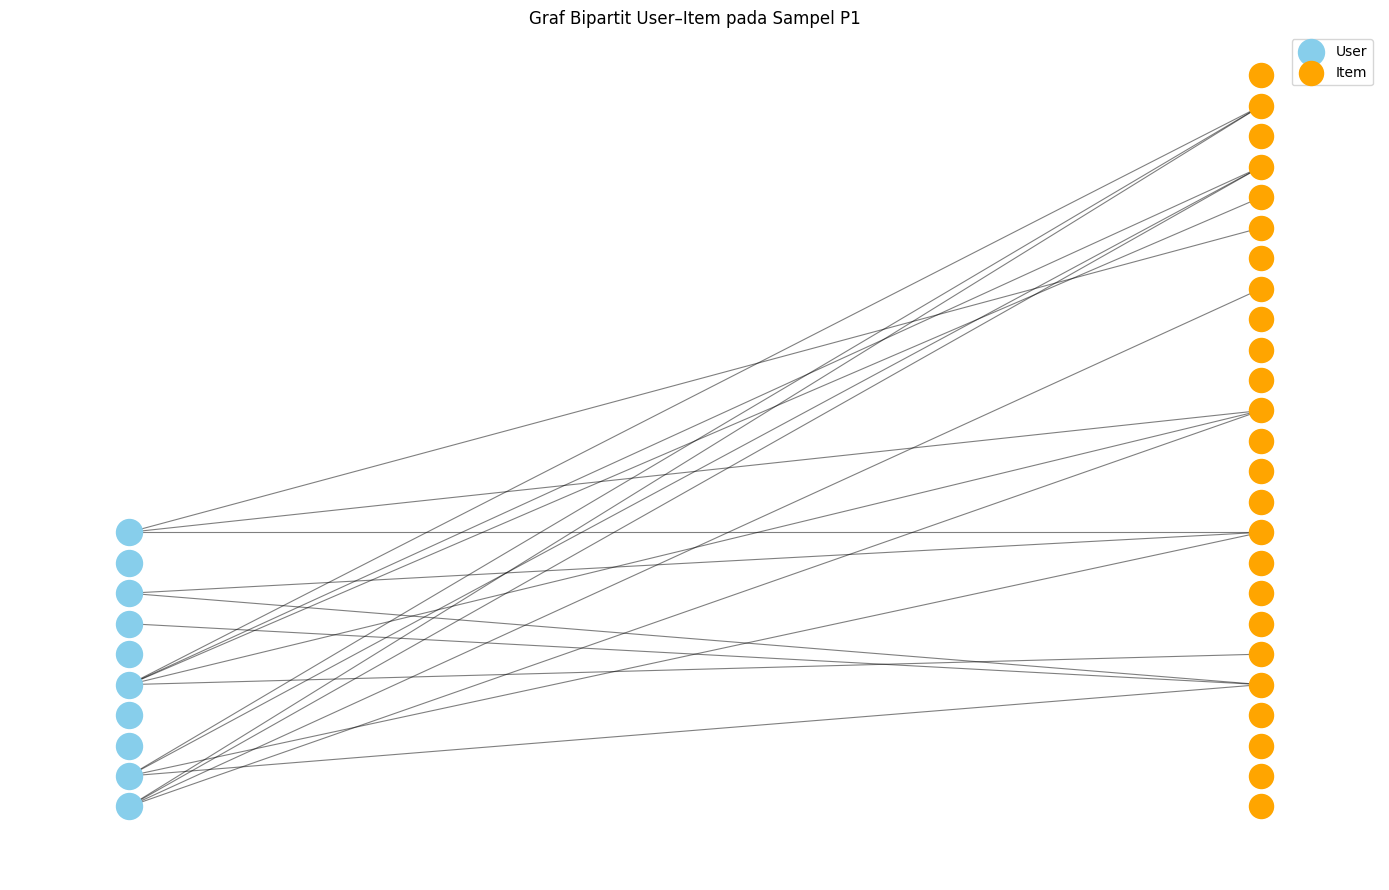

In [ ]:
interaksi_per_user = user_item.groupby("visitorid")["itemid"].nunique()

top_users = interaksi_per_user.nlargest(
    min(15, len(interaksi_per_user))
).index.tolist()

interaksi_per_item = user_item.groupby("itemid")["visitorid"].nunique()

top_items = interaksi_per_item.nlargest(
    min(25, len(interaksi_per_item))
).index.tolist()

plot_data = user_item[
    user_item["visitorid"].isin(top_users)
    & user_item["itemid"].isin(top_items)
]

G_user_item = nx.Graph()

G_user_item.add_nodes_from(
    [f"U_{u}" for u in top_users],
    node_type="User"
)

G_user_item.add_nodes_from(
    [f"I_{i}" for i in top_items],
    node_type="Item"
)

G_user_item.add_edges_from(
    (f"U_{row.visitorid}", f"I_{row.itemid}")
    for row in plot_data.itertuples(index=False)
)

print("Jumlah node pada graf sampel:", G_user_item.number_of_nodes())
print("Jumlah edge pada graf sampel:", G_user_item.number_of_edges())

pos = {}

for idx, user in enumerate(top_users):
    pos[f"U_{user}"] = (0, idx)

for idx, item in enumerate(top_items):
    pos[f"I_{item}"] = (1, idx)

plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(
    G_user_item, pos,
    nodelist=[f"U_{u}" for u in top_users],
    node_size=350,
    node_color="skyblue",
    label="User"
)

nx.draw_networkx_nodes(
    G_user_item, pos,
    nodelist=[f"I_{i}" for i in top_items],
    node_size=300,
    node_color="orange",
    label="Item"
)

nx.draw_networkx_edges(
    G_user_item, pos,
    alpha=0.5,
    width=0.8
)

plt.title("Graf Bipartit User–Item pada Sampel P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

VSM users dibentuk dengan mempresentasikan setiap visitor sebagai baris dan item sebagai kolom. nilai matriks bersifat biner, 1 adalah nilai visitor pernah berinteraksi dengan item sedangkan 0 adalah nilai tidak ada interaksi. visualisasi NetworkX menunjukkan adanya hubungan antara Visitor dan Item pada sampel data. tiap edge menunjukkan adanya interaksi visitor dan item.

BAGIAN 5 - VSM ITEM

In [18]:
item_to_idx = {item: idx for idx, item in enumerate(items)}
user_to_idx = {user: idx for idx, user in enumerate(users)}

rows = user_item["itemid"].map(item_to_idx).to_numpy()
cols = user_item["visitorid"].map(user_to_idx).to_numpy()
values_item = np.ones(len(user_item), dtype=np.int8)

item_vsm = csr_matrix(
    (values_item, (rows, cols)),
    shape=(len(items), len(users)),
    dtype=np.int8
)

print("=== KARAKTERISTIK USER VSM ===")
print("Dimensi matriks:", item_vsm.ndim)
print("Shape matriks:", item_vsm.shape)
print("Jumlah baris (User):", item_vsm.shape[0])
print("Jumlah kolom (fitur Item):", item_vsm.shape[1])
print("Jumlah nilai nonzero:", item_vsm.nnz)

total_elemen = item_vsm.shape[0] * item_vsm.shape[1]
sparsity = 1 - (item_vsm.nnz / total_elemen)

print(f"Sparsity matriks: {sparsity:.6%}")
print(f"Persentase interaksi terisi: {(1-sparsity):.6%}")

=== KARAKTERISTIK USER VSM ===
Dimensi matriks: 2
Shape matriks: (61143, 108585)
Jumlah baris (User): 61143
Jumlah kolom (fitur Item): 108585
Jumlah nilai nonzero: 155574
Sparsity matriks: 99.997657%
Persentase interaksi terisi: 0.002343%


In [19]:
jumlah_item_sampel = min(5, len(items))
jumlah_user_sampel = min(10, len(users))

sampel_item_vsm = pd.DataFrame(
    item_vsm[:jumlah_item_sampel, :jumlah_user_sampel].toarray(),
    index=items[:jumlah_item_sampel],
    columns=users[:jumlah_user_sampel]
)

print("Contoh sebagian matriks VSM Item:")
display(sampel_item_vsm)

Contoh sebagian matriks VSM Item:


,8,14,19,24,49,72,135,141,154,170
6,0,0,0,0,0,0,0,0,0,0
15,0,0,0,0,0,0,0,0,0,0
25,0,0,0,0,0,0,0,0,0,0
29,0,0,0,0,0,0,0,0,0,0
32,0,0,0,0,0,0,0,0,0,0


Jumlah node graf sampel: 40
Jumlah edge graf sampel: 21


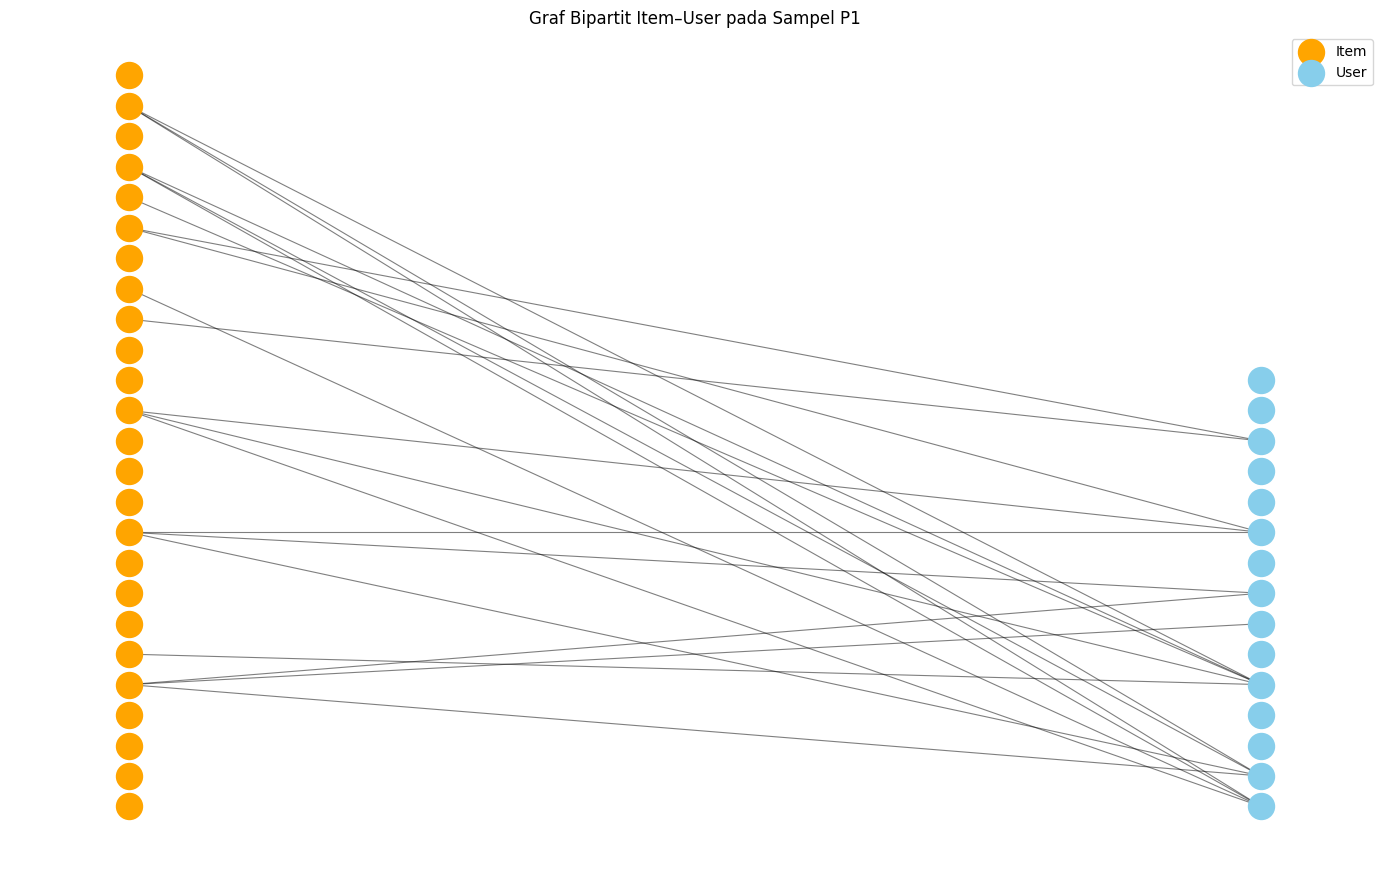

In [23]:
# Pilih 20 Item dengan jumlah Visitor unik terbanyak
interaksi_per_item = user_item.groupby("itemid")["visitorid"].nunique()
top_items_plot = interaksi_per_item.nlargest(
    min(25, len(interaksi_per_item))
).index.tolist()

# Pilih 15 User yang paling aktif
interaksi_per_user = user_item.groupby("visitorid")["itemid"].nunique()
top_users_plot = interaksi_per_user.nlargest(
    min(15, len(interaksi_per_user))
).index.tolist()

plot_item_data = user_item[
    user_item["itemid"].isin(top_items_plot)
    & user_item["visitorid"].isin(top_users_plot)
]

G_item_user = nx.Graph()

G_item_user.add_nodes_from(
    [f"I_{i}" for i in top_items_plot],
    node_type="Item"
)
G_item_user.add_nodes_from(
    [f"U_{u}" for u in top_users_plot],
    node_type="User"
)

G_item_user.add_edges_from(
    (f"I_{row.itemid}", f"U_{row.visitorid}")
    for row in plot_item_data.itertuples(index=False)
)

print("Jumlah node graf sampel:", G_item_user.number_of_nodes())
print("Jumlah edge graf sampel:", G_item_user.number_of_edges())

pos_item = {}

for idx, item in enumerate(top_items_plot):
    pos_item[f"I_{item}"] = (0, idx)

for idx, user in enumerate(top_users_plot):
    pos_item[f"U_{user}"] = (1, idx)

plt.figure(figsize=(14, 9))

nx.draw_networkx_nodes(
    G_item_user, pos_item,
    nodelist=[f"I_{i}" for i in top_items_plot],
    node_size=350,
    node_color="orange",
    label="Item"
)

nx.draw_networkx_nodes(
    G_item_user, pos_item,
    nodelist=[f"U_{u}" for u in top_users_plot],
    node_size=350,
    node_color="skyblue",
    label="User"
)

nx.draw_networkx_edges(
    G_item_user, pos_item,
    alpha=0.5,
    width=0.8
)

plt.title("Graf Bipartit Item–User pada Sampel P1")
plt.legend()
plt.axis("off")
plt.tight_layout()
plt.show()

BAGIAN 6 - PERBANDINGAN VSM USER DAN VSM ITEM

In [24]:
# Perbandingan karakteristik matriks
total_elemen_user = user_vsm.shape[0] * user_vsm.shape[1]
total_elemen_item = item_vsm.shape[0] * item_vsm.shape[1]

sparsity_user = 1 - (user_vsm.nnz / total_elemen_user)
sparsity_item = 1 - (item_vsm.nnz / total_elemen_item)

perbandingan_vsm = pd.DataFrame({
    "Karakteristik": [
        "Jumlah dimensi",
        "Jumlah baris",
        "Jumlah kolom",
        "Total elemen matriks",
        "Jumlah nilai nonzero",
        "Sparsity (%)",
        "Ukuran penyimpanan (MB)"
    ],
    "VSM User": [
        user_vsm.ndim,
        user_vsm.shape[0],
        user_vsm.shape[1],
        total_elemen_user,
        user_vsm.nnz,
        sparsity_user * 100,
        (
            user_vsm.data.nbytes
            + user_vsm.indices.nbytes
            + user_vsm.indptr.nbytes
        ) / (1024 ** 2)
    ],
    "VSM Item": [
        item_vsm.ndim,
        item_vsm.shape[0],
        item_vsm.shape[1],
        total_elemen_item,
        item_vsm.nnz,
        sparsity_item * 100,
        (
            item_vsm.data.nbytes
            + item_vsm.indices.nbytes
            + item_vsm.indptr.nbytes
        ) / (1024 ** 2)
    ]
})

display(perbandingan_vsm.round(4))

,Karakteristik,VSM User,VSM Item
0,Jumlah dimensi,2.000000e+00,2.000000e+00
1,Jumlah baris,1.085850e+05,6.114300e+04
2,Jumlah kolom,6.114300e+04,1.085850e+05
3,Total elemen matriks,6.639213e+09,6.639213e+09
4,Jumlah nilai nonzero,1.555740e+05,1.555740e+05
5,Sparsity (%),9.999770e+01,9.999770e+01
6,Ukuran penyimpanan (MB),1.156100e+00,9.751000e-01


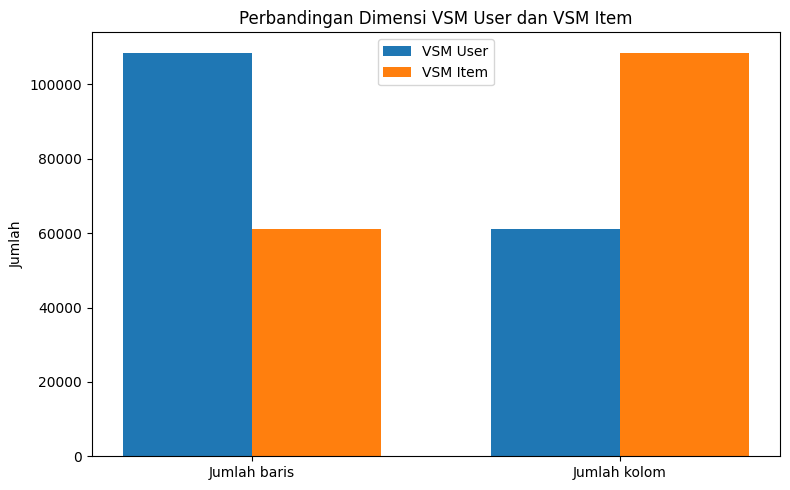

In [25]:
labels = ["Jumlah baris", "Jumlah kolom"]

user_values = [
    user_vsm.shape[0],
    user_vsm.shape[1]
]

item_values = [
    item_vsm.shape[0],
    item_vsm.shape[1]
]

x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width / 2, user_values, width, label="VSM User")
plt.bar(x + width / 2, item_values, width, label="VSM Item")

plt.xticks(x, labels)
plt.ylabel("Jumlah")
plt.title("Perbandingan Dimensi VSM User dan VSM Item")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
print(
    "Apakah VSM Item merupakan transpose VSM User?",
    (item_vsm != user_vsm.T).nnz == 0
)

print("Shape VSM User:", user_vsm.shape)
print("Shape transpose VSM User:", user_vsm.T.shape)
print("Shape VSM Item:", item_vsm.shape)

print("Jumlah interaksi VSM User:", user_vsm.nnz)
print("Jumlah interaksi VSM Item:", item_vsm.nnz)

Apakah VSM Item merupakan transpose VSM User? True
Shape VSM User: (108585, 61143)
Shape transpose VSM User: (61143, 108585)
Shape VSM Item: (61143, 108585)
Jumlah interaksi VSM User: 155574
Jumlah interaksi VSM Item: 155574


berdasarkan hasil kedua matriks tersebut memiliki jumlah nilai nonzero dan tingkat sparsity yang sama apabila dibangun dari pasangan interaksi yang sama. perbedaan utamanya terletak pada orientasi data dan tujuan analisis, bukan pada jumlah informasi interaksi yang direpresentasikan. oleh karena itu, pemilihan VSM yang lebih sesuai ditentukan oleh tujuan analisis dan strategi rekomendasi yang digunakan.

BAGIAN 7 - SIMILARTY

In [27]:
from sklearn.metrics.pairwise import cosine_similarity

driver_similarity = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

with driver_similarity.session(database="neo4j") as session:
    result = session.run("""
        MATCH (i:Item)
        RETURN keys(i) AS properti, i
        LIMIT 3
    """)

    for record in result:
        print("Properti:", record["properti"])
        print("Contoh node:", dict(record["i"]))
        print("-" * 40)

Properti: ['itemid']
Contoh node: {'itemid': 5206}
----------------------------------------
Properti: ['itemid']
Contoh node: {'itemid': 10572}
----------------------------------------
Properti: ['itemid']
Contoh node: {'itemid': 255275}
----------------------------------------


In [28]:
assert "item_vsm" in globals(), "Jalankan dahulu bagian 5: VSM Item."
assert "items" in globals(), "Daftar Item belum tersedia."
assert "user_item" in globals(), "Data pasangan User-Item belum tersedia."

visitor_per_item = (
    user_item.groupby("itemid")["visitorid"]
    .nunique()
)

reference_item = visitor_per_item.idxmax()
reference_idx = item_to_idx[reference_item]

print("Item referensi:", reference_item)
print("Jumlah Visitor unik:", visitor_per_item.loc[reference_item])
print("Shape VSM Item:", item_vsm.shape)

Item referensi: 290250
Jumlah Visitor unik: 275
Shape VSM Item: (61143, 108585)


In [30]:
similarity_scores = cosine_similarity(
    item_vsm[reference_idx],
    item_vsm
).ravel()

similarity_scores[reference_idx] = -1

top_indices = np.argsort(similarity_scores)[::-1][:5]

top5_similarity = pd.DataFrame({
    "reference_itemid": [reference_item] * len(top_indices),
    "similar_itemid": [items[idx] for idx in top_indices],
    "similarity": [float(similarity_scores[idx]) for idx in top_indices]
})

display(top5_similarity)

,reference_itemid,similar_itemid,similarity
0,290250,396963,0.419411
1,290250,60057,0.128932
2,290250,61512,0.123091
3,290250,279493,0.080904
4,290250,294887,0.060302


In [32]:
query_save_similarity = """
MATCH (a:Item {itemid: $source_id})
MATCH (b:Item {itemid: $target_id})
MERGE (a)-[r:SIMILAR_TO]->(b)
SET r.similarity = $similarity,
    r.method = 'cosine_similarity',
    r.period = 'P1'
RETURN a.itemid AS item_sumber,
       b.itemid AS item_mirip,
       r.similarity AS similarity,
       type(r) AS jenis_relasi
"""

saved_results = []

with driver_similarity.session(database="neo4j") as session:
    for row in top5_similarity.to_dict("records"):
        result = session.run(
            query_save_similarity,
            source_id=int(row["reference_itemid"]),
            target_id=int(row["similar_itemid"]),
            similarity=float(row["similarity"])
        )
        saved_results.extend([dict(record) for record in result])

display(pd.DataFrame(saved_results))

,item_sumber,item_mirip,similarity,jenis_relasi
0,290250,396963,0.419411,SIMILAR_TO
1,290250,60057,0.128932,SIMILAR_TO
2,290250,61512,0.123091,SIMILAR_TO
3,290250,279493,0.080904,SIMILAR_TO
4,290250,294887,0.060302,SIMILAR_TO


In [33]:
query_verify_similarity = """
MATCH (a:Item)-[r:SIMILAR_TO]->(b:Item)
WHERE a.itemid = $reference_id
  AND r.period = 'P1'
RETURN a.itemid AS item_referensi,
       b.itemid AS item_mirip,
       r.similarity AS similarity,
       r.method AS metode
ORDER BY r.similarity DESC
LIMIT 5
"""

with driver_similarity.session(database="neo4j") as session:
    verified = list(session.run(
        query_verify_similarity,
        reference_id=int(reference_item)
    ))

display(pd.DataFrame([dict(record) for record in verified]))

,item_referensi,item_mirip,similarity,metode
0,290250,396963,0.419411,cosine_similarity
1,290250,60057,0.128932,cosine_similarity
2,290250,61512,0.123091,cosine_similarity
3,290250,279493,0.080904,cosine_similarity
4,290250,294887,0.060302,cosine_similarity


Similarity antar-Item dihitung menggunakan Cosine Similarity berdasarkan VSM Item periode P1. Setiap Item direpresentasikan sebagai vektor biner yang menunjukkan Visitor yang pernah berinteraksi dengan Item tersebut. Item referensi dipilih berdasarkan jumlah Visitor unik terbanyak. lima item dengan nilai similarity tertinggi dipilih sebagai item yang memiliki pola interaksi visitor paling mirip. nilai similarity yang tinggi menunjukkan kemiripan pola Visitor yang berinteraksi dengan dua Item. Namun, kemiripan tersebut tidak otomatis membuktikan bahwa kedua Item memiliki karakteristik produk yang sama atau bahwa pengguna pasti akan membeli Item yang direkomendasikan.

## 2.2

BAGIAN 1 - KNN

In [34]:
import numpy as np
import pandas as pd
from collections import Counter

In [36]:
df_p1 = pd.read_csv("P1_training.csv")

print("Ukuran data P1:", df_p1.shape)
print("Kolom dataset:", df_p1.columns.tolist())

display(df_p1.head())

Ukuran data P1: (196538, 6)
Kolom dataset: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime']


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1432253007974,973650,view,342736,NaN,2015-05-22 00:03:27.974
1,1432252945016,117211,view,364251,NaN,2015-05-22 00:02:25.016
2,1432252944810,11580,view,152863,NaN,2015-05-22 00:02:24.810
3,1432253005273,1192719,view,193380,NaN,2015-05-22 00:03:25.273
4,1432252838573,527307,view,87063,NaN,2015-05-22 00:00:38.573


In [ ]:
from scipy.sparse import csr_matrix

user_item = (
    df_p1[["visitorid", "itemid"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

users = sorted(user_item["visitorid"].unique())
items = sorted(user_item["itemid"].unique())

user_to_idx = {user: idx for idx, user in enumerate(users)}
item_to_idx = {item: idx for idx, item in enumerate(items)}

rows = user_item["visitorid"].map(user_to_idx).to_numpy()
cols = user_item["itemid"].map(item_to_idx).to_numpy()

values = np.ones(len(user_item), dtype=np.float32)

user_vsm = csr_matrix(
    (values, (rows, cols)),
    shape=(len(users), len(items)),
    dtype=np.float32
)

print("Jumlah user:", len(users))
print("Jumlah item:", len(items))
print("Bentuk User VSM:", user_vsm.shape)
print("Jumlah interaksi:", user_vsm.nnz)
print("Ukuran data sparse: {:.2f} MB".format(
    (user_vsm.data.nbytes +
     user_vsm.indices.nbytes +
     user_vsm.indptr.nbytes) / (1024 ** 2)
))

Jumlah user: 108585
Jumlah item: 61143
Bentuk User VSM: (108585, 61143)
Jumlah interaksi: 155574
Ukuran data sparse: 1.60 MB


In [40]:
import numpy as np

class KNN:
    def __init__(self, k=5):
        self.k = k
        self.X_train = None
        self.squared_norms = None

    def fit(self, X):
        # Simpan dalam format sparse CSR
        self.X_train = X.tocsr().astype(np.float32)

        # Panjang kuadrat setiap vektor user
        self.squared_norms = np.asarray(
            self.X_train.multiply(self.X_train).sum(axis=1)
        ).ravel()

    def _euclidean_distances(self, x):
        # Hasil dot product antara semua user dan user target
        dot_products = (self.X_train @ x.T).toarray().ravel()

        # Kuadrat jarak Euclidean
        target_norm = float(x.multiply(x).sum())

        squared_distances = (
            self.squared_norms
            + target_norm
            - 2 * dot_products
        )

        # Menghindari nilai negatif akibat pembulatan numerik
        squared_distances = np.maximum(squared_distances, 0)

        return np.sqrt(squared_distances)

    def kneighbors(self, x, exclude_idx=None):
        distances = self._euclidean_distances(x)

        # Jangan memasukkan user target sebagai tetangganya sendiri
        if exclude_idx is not None:
            distances[exclude_idx] = np.inf

        k_indices = np.argsort(distances)[:self.k]

        return k_indices, distances[k_indices]

In [41]:
random_state = 42
rng = np.random.default_rng(random_state)

target_idx = int(rng.integers(0, len(users)))
target_user = users[target_idx]

print("Random state:", random_state)
print("User target:", target_user)
print("Indeks user:", target_idx)
print("Jumlah item yang pernah diinteraksikan:",
      int(user_vsm[target_idx].nnz))

Random state: 42
User target: 124746
Indeks user: 9691
Jumlah item yang pernah diinteraksikan: 1


In [42]:
k = 5

knn_model = KNN(k=k)
knn_model.fit(user_vsm)

# Ambil satu baris sparse untuk user target
target_vector = user_vsm[target_idx]

neighbor_indices, neighbor_distances = knn_model.kneighbors(
    target_vector,
    exclude_idx=target_idx
)

df_neighbors = pd.DataFrame({
    "peringkat": range(1, k + 1),
    "visitorid": [users[idx] for idx in neighbor_indices],
    "euclidean_distance": neighbor_distances
})

display(df_neighbors)

,peringkat,visitorid,euclidean_distance
0,1,232,1.414214
1,2,235,1.414214
2,3,236,1.414214
3,4,251,1.414214
4,5,253,1.414214


In [43]:
from collections import Counter

# Item yang pernah diinteraksikan user target
target_items = set(
    user_item.loc[
        user_item["visitorid"] == target_user,
        "itemid"
    ].tolist()
)

recommendation_scores = Counter()

for neighbor_idx, distance in zip(
    neighbor_indices, neighbor_distances
):
    neighbor_user = users[neighbor_idx]

    # Bobot lebih besar untuk tetangga yang lebih dekat
    weight = 1 / (1 + float(distance))

    neighbor_items = user_item.loc[
        user_item["visitorid"] == neighbor_user,
        "itemid"
    ].tolist()

    for item_id in neighbor_items:
        if item_id not in target_items:
            recommendation_scores[item_id] += weight

ranked_items = sorted(
    recommendation_scores.items(),
    key=lambda x: (-x[1], x[0])
)

top_recommendations = ranked_items[:3]

df_recommendations = pd.DataFrame(
    top_recommendations,
    columns=["itemid", "skor_rekomendasi"]
)

df_recommendations.insert(
    0,
    "peringkat",
    range(1, len(df_recommendations) + 1)
)

print("User target:", target_user)
print("Nilai k:", k)
print("Jumlah kandidat rekomendasi:", len(ranked_items))

display(df_recommendations)

User target: 124746
Nilai k: 5
Jumlah kandidat rekomendasi: 5


,peringkat,itemid,skor_rekomendasi
0,1,179740,0.414214
1,2,210318,0.414214
2,3,211393,0.414214


BAGIAN 2 - HIT@5 DAN NDCG@5

In [45]:
import pandas as pd
import numpy as np

# Membaca data testing
df_p2 = pd.read_csv("P2_testing.csv")

print("Ukuran data P2:", df_p2.shape)
print("Kolom:", df_p2.columns.tolist())

display(df_p2.head())

Ukuran data P2: (177662, 6)
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime']


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1438494458916,1190029,view,338463,NaN,2015-08-02 05:47:38.916
1,1438494443158,1140512,view,184998,NaN,2015-08-02 05:47:23.158
2,1438493656705,1111168,view,456909,NaN,2015-08-02 05:34:16.705
3,1438495148775,938839,view,73918,NaN,2015-08-02 05:59:08.775
4,1438494854924,505655,view,409804,NaN,2015-08-02 05:54:14.924


In [46]:
# Memastikan user target tersedia
print("User target:", target_user)

# Mengambil item yang diinteraksikan user target pada P2
relevant_items = set(
    df_p2.loc[
        df_p2["visitorid"] == target_user,
        "itemid"
    ].dropna().tolist()
)

print("Jumlah item relevan pada P2:", len(relevant_items))
print("Contoh item relevan:", list(relevant_items)[:10])

User target: 124746
Jumlah item relevan pada P2: 0
Contoh item relevan: []


In [47]:
# Ambil maksimal 5 rekomendasi teratas dari hasil KNN
recommendations_at_5 = [
    item_id for item_id, score in ranked_items[:5]
]

print("Daftar rekomendasi @5:", recommendations_at_5)
print("Jumlah rekomendasi:", len(recommendations_at_5))

Daftar rekomendasi @5: [179740, 210318, 211393, 281036, 365030]
Jumlah rekomendasi: 5


In [48]:
# Hit@5 untuk user target
if len(relevant_items) == 0:
    hit_at_5 = np.nan
    print("Hit@5 tidak dapat dihitung: tidak ada interaksi relevan pada P2.")
else:
    hit_at_5 = int(
        any(item in relevant_items for item in recommendations_at_5)
    )
    print("Hit@5:", hit_at_5)

Hit@5 tidak dapat dihitung: tidak ada interaksi relevan pada P2.


In [49]:
def calculate_ndcg_at_k(recommendations, relevant_items, k=5):
    # Tidak dapat dievaluasi jika tidak ada item relevan
    if len(relevant_items) == 0:
        return np.nan

    # Relevansi setiap item berdasarkan urutan rekomendasi
    relevance = [
        1 if item in relevant_items else 0
        for item in recommendations[:k]
    ]

    # DCG aktual
    dcg = sum(
        rel / np.log2(rank + 1)
        for rank, rel in enumerate(relevance, start=1)
    )

    # DCG ideal: semua item relevan berada di posisi teratas
    ideal_relevance = [1] * min(len(relevant_items), k)

    idcg = sum(
        rel / np.log2(rank + 1)
        for rank, rel in enumerate(ideal_relevance, start=1)
    )

    return dcg / idcg if idcg > 0 else 0.0


ndcg_at_5 = calculate_ndcg_at_k(
    recommendations_at_5,
    relevant_items,
    k=5
)

print("NDCG@5:", ndcg_at_5)

NDCG@5: nan


In [50]:
evaluation_result = pd.DataFrame([{
    "visitorid": target_user,
    "jumlah_item_relevan_P2": len(relevant_items),
    "jumlah_rekomendasi": len(recommendations_at_5),
    "Hit@5": hit_at_5,
    "NDCG@5": ndcg_at_5
}])

display(evaluation_result)

,visitorid,jumlah_item_relevan_P2,jumlah_rekomendasi,Hit@5,NDCG@5
0,124746,0,5,NaN,NaN


In [51]:
evaluation_result.to_csv(
    "hasil_KNN.csv",
    index=False
)

print("Hasil evaluasi tersimpan: hasil_KNN.csv")

Hasil evaluasi tersimpan: hasil_KNN.csv
